In [35]:
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from skimage import exposure, filters
from scipy import ndimage as ndi
from skimage import measure, segmentation
from skimage.feature import peak_local_max
from skimage import morphology

Shape: (21, 512, 512)
Data type: uint8
Intensity range: 0 255


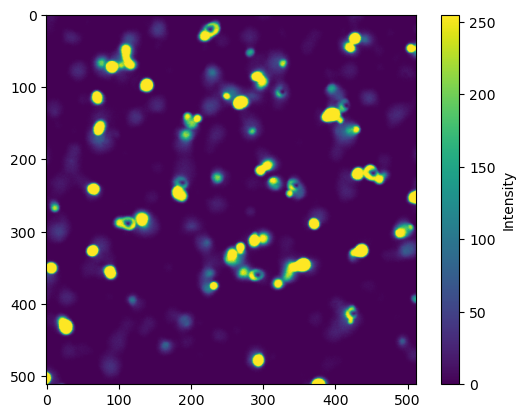

In [13]:
raw = tifffile.imread("data/Apt2_1.tif")

print("Shape:", raw.shape)
print("Data type:", raw.dtype)
print("Intensity range:", raw.min(), raw.max())

# Display the first frame of a grayscale TIFF stack,
# or the image itself if it contains a single 2D frame.
image = raw[1].astype(float, copy=True)

plt.imshow(image, cmap="viridis")
plt.colorbar(label="Intensity")
plt.show()

# 1) Percentile normalization

In [24]:
original = raw[0].astype(np.float64, copy=True)

# Same normalization and smoothing as the global comparison.
low, high = np.percentile(original, (2, 98))
if high <= low:
    raise ValueError("Percentile range is constant; choose wider percentiles.")

normalized = np.clip((original - low) / (high - low), 0, 1)

# 2) Gaussian smooth
The purpose is to reduce small intensity fluctuations while preserving boundaries and gaps. 

Imagine a single unusually bright pixel surrounded by darker pixels. Gaussian filtering replaces its brightness with a weighted average of the surrounding values. Nearby pixels contribute more than distant ones, following a bell-shaped weighting pattern.

This reduces isolated fluctuations, but it also softens real edges. The filter cannot distinguish noise from a small biological feature.

sigma is the main parameter to tune. It describes the spread of the weighting, rather than the full filter width.

| Parameter | Plain meaning | Effect |
|---|---|---|
| `sigma` | How widely a pixel consults its neighbours, measured in pixels | Higher values produce more smoothing and blur. |
| `preserve_range` | Whether to retain the original intensity scale | `True` avoids automatic intensity rescaling; filtering still changes individual values. |
| `mode` | How to handle neighbours beyond the image edges | Usually leave the default initially. |

In [25]:
smooth = filters.gaussian(normalized, sigma=0.5, preserve_range=True)


# 3) CLAHE adjustment

CLAHE adjusts contrast separately in different neighbourhoods.

Imagine a photograph with a dark corner and a bright corner. One adjustment for the whole photograph may leave the dark corner difficult to see. CLAHE adjusts contrast using smaller regions, allowing faint details to become more visible locally.

A histogram counts how many pixels have each brightness. CLAHE builds local histograms, redistributes brightness values to improve contrast, and blends neighbouring adjustments to avoid abrupt tile boundaries.

“Contrast limited” means it restricts excessive histogram enhancement. This helps control noise amplification; it does not repair saturated pixels.

| Parameter | Plain meaning | Effect |
|---|---|---|
| `kernel_size` | Size of the regions used to assess local contrast | Smaller regions give more local adaptation; larger regions use broader context. |
| `clip_limit` | How much contrast enhancement is allowed | Higher values allow stronger enhancement, including unwanted fluctuations. |
| `nbins` | Number of brightness categories in each histogram | Usually leave at `256` initially. |

In [26]:
# LOCAL contrast enhancement.
local_image = exposure.equalize_adapthist(
    smooth,
    kernel_size=128,   # Contextual tile size in pixels.
    clip_limit=0.01,  # Higher values allow stronger contrast enhancement.
)

# 4) Otsu threshold
Otsu chooses one intensity threshold from the image histogram; pixels above it become foreground. This produces a binary foreground mask, before separating touching cells.

Imagine listing every pixel by brightness, from darkest to brightest. Otsu tests possible dividing points and selects the one that best separates the brightness distribution into two groups. Mathematically, it minimizes the weighted brightness variation within those groups.

| Parameter or choice | Plain meaning | What to do |
|---|---|---|
| `nbins` | Number of brightness categories used for floating-point input | Start with `256`. |
| Input image | Which brightness distribution Otsu receives | Normalization, smoothing and CLAHE all influence its result. |
| Optional threshold multiplier | A manual adjustment after calculating Otsu | Below `1` includes more pixels; above `1` includes fewer. This is an added tuning choice. |

In [27]:
# Calculate and apply Otsu's threshold.
local_threshold = filters.threshold_otsu(local_image)
local_mask = local_image > local_threshold

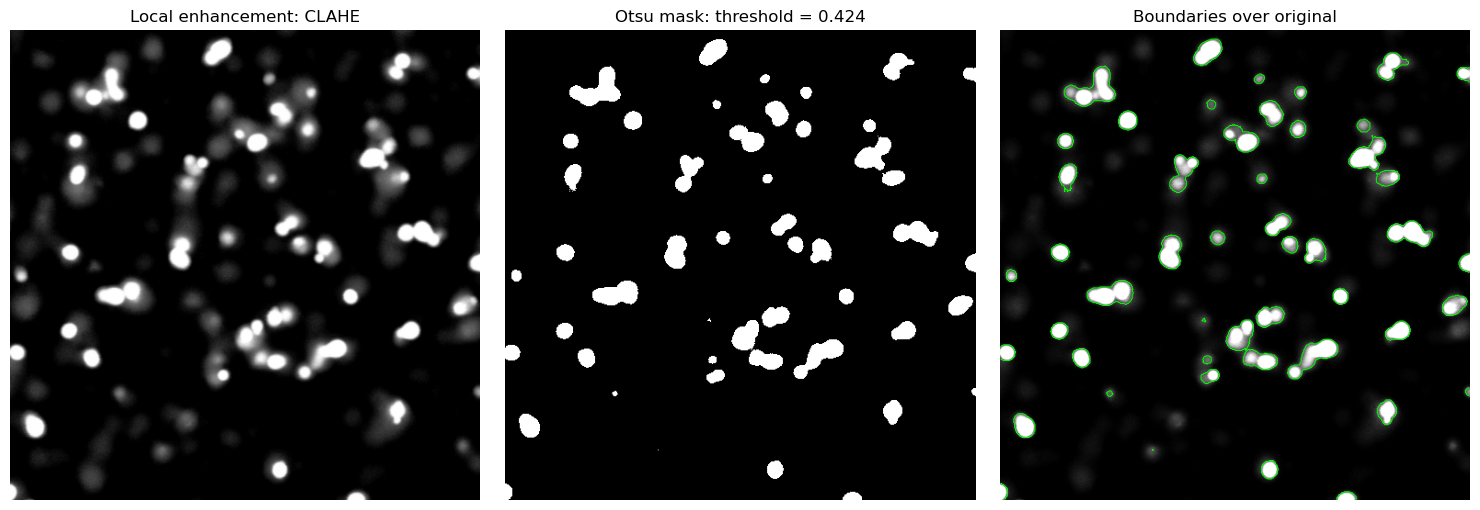

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(local_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Local enhancement: CLAHE")

axes[1].imshow(local_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Otsu mask: threshold = {local_threshold:.3f}")

axes[2].imshow(
    original, cmap="gray", vmin=original.min(), vmax=original.max()
)
axes[2].contour(local_mask.astype(float), levels=[0.5],
                colors="lime", linewidths=0.7)
axes[2].set_title("Boundaries over original")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

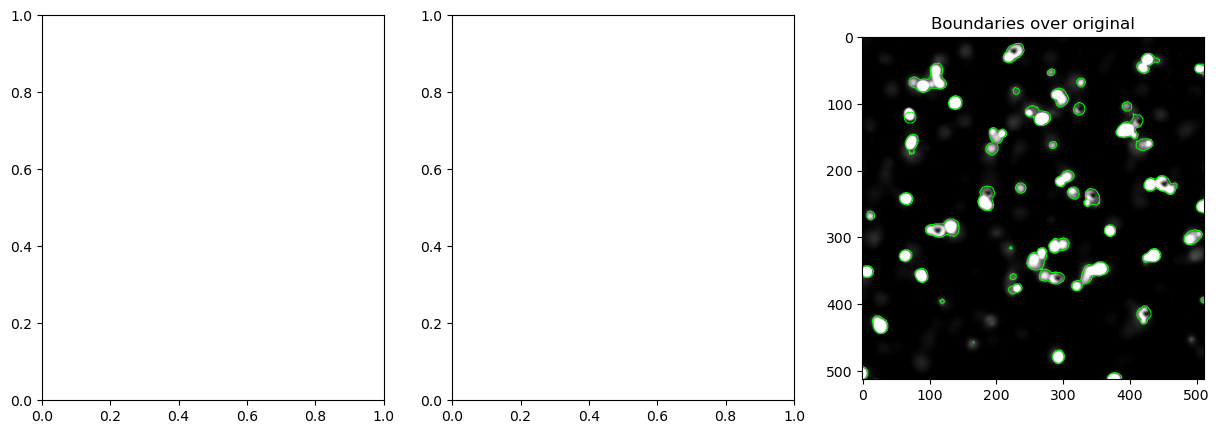

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
original = raw[1].astype(np.float64, copy=True)

axes[2].imshow(
    original, cmap="gray", vmin=original.min(), vmax=original.max()
)
axes[2].contour(local_mask.astype(float), levels=[0.5],
                colors="lime", linewidths=0.7)
axes[2].set_title("Boundaries over original")
plt.show()

# 5) Remove small objects

| Parameter | Meaning | What to watch |
|---|---|---|
| `min_cell_area` | Smallest area you want to retain | Too high removes small real cells; too low retains unwanted specks. |
| `connectivity` | Which neighbouring pixels count as touching | `1`: shared edges. `2`: shared edges or corners, in 2D. |

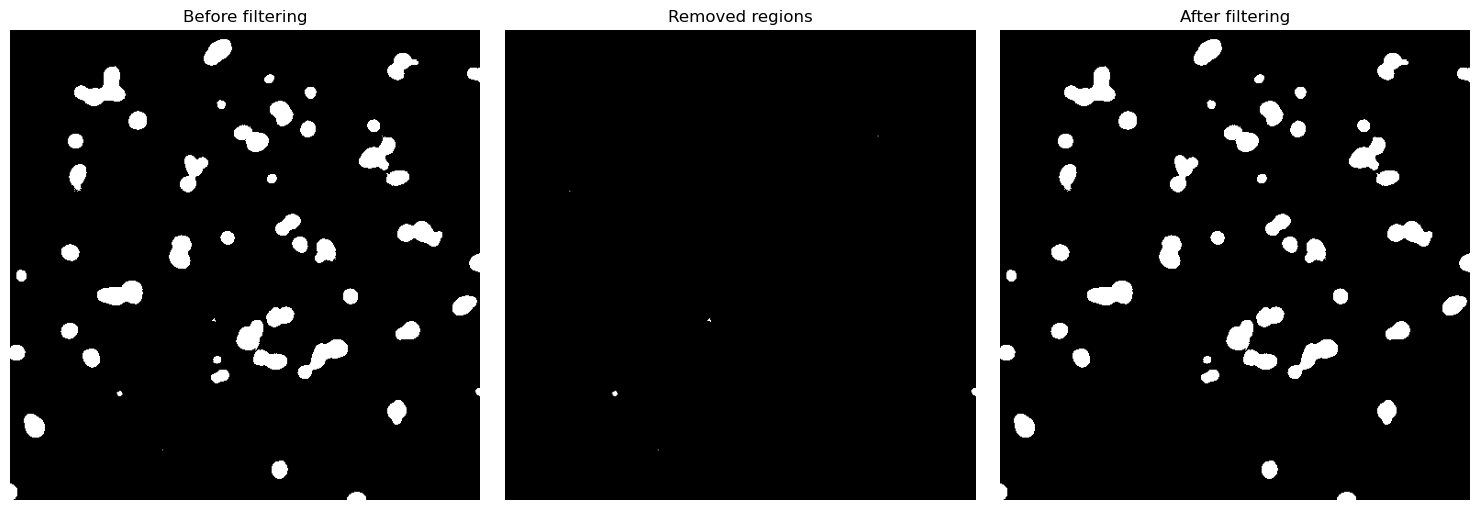

In [33]:
min_cell_area = 40  # Example: retain regions containing at least 40 pixels.

clean_mask = morphology.remove_small_objects(
    local_mask.astype(bool),
    max_size=min_cell_area - 1,
    connectivity=2,  # Pixels touching diagonally also belong together.
)

removed_mask = local_mask.astype(bool) & ~clean_mask

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image, title in zip(
    axes,
    [local_mask, removed_mask, clean_mask],
    ["Before filtering", "Removed regions", "After filtering"],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 6) Watershed
Watershed divides a connected region into separate objects.

Code steps:
1. Build a distance map. Each foreground pixel receives a value describing its distance from the nearest background pixel. Values are small near the edges and larger deep inside the object.
2. Find candidate centres. Peaks in that distance map become seeds. A peanut-shaped region may have one peak in each lobe.
3. Grow regions from the seeds. Each seed claims surrounding foreground pixels. Where competing regions meet, watershed places a boundary.

In this implementation, watershed uses the shape of your binary mask, rather than the fluorescence brightness inside it.

| Control | Meaning | Effect |
|---|---|---|
| `min_peak_distance` | How close candidate centres may be within a connected region | Smaller values generally allow more splits; larger values generally allow fewer. |
| Foreground mask | The area watershed is allowed to divide | Missing cell parts cannot be recovered by this operation. |
| Seed placement | Where separate regions start growing | Ideally, each actual cell has one seed. |

Retained objects: 60


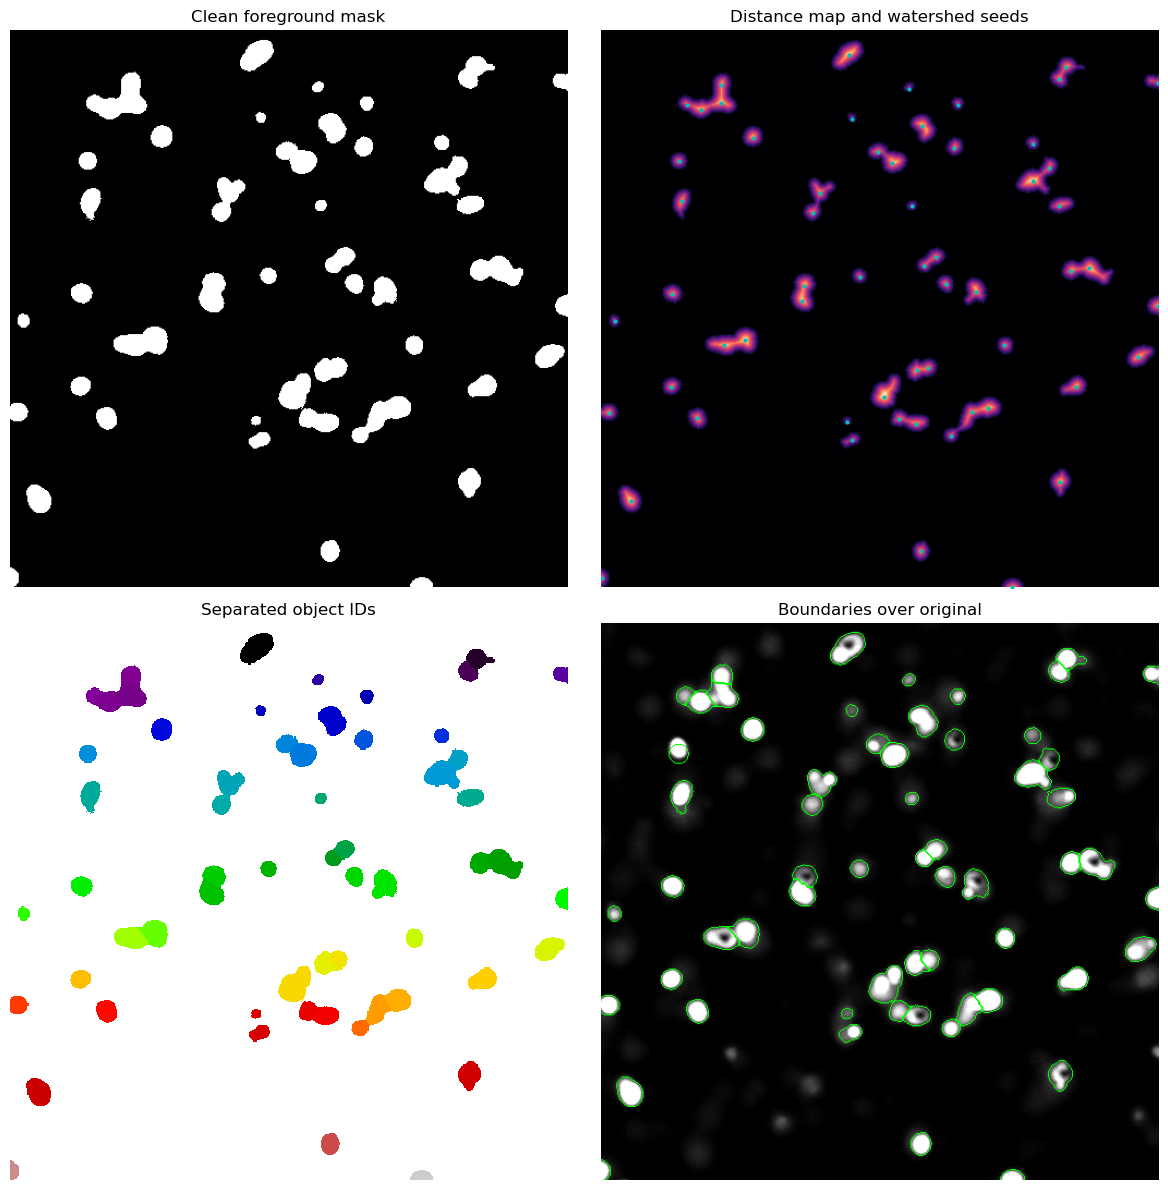

In [34]:
min_peak_distance = 6  # Seed separation in pixels; test this value.

# Give disconnected foreground regions different IDs.
components = measure.label(clean_mask, connectivity=2)

# Larger values occur deeper inside each foreground region.
distance = ndi.distance_transform_edt(clean_mask)

# Find candidate centres within each connected region.
peaks = peak_local_max(
    distance,
    min_distance=min_peak_distance,
    labels=components,
    exclude_border=False,
)

# Give every seed its own integer ID.
markers = np.zeros(clean_mask.shape, dtype=np.int32)
markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)

# Split the foreground into individual labelled regions.
cell_labels = segmentation.watershed(
    -distance,
    markers=markers,
    mask=clean_mask,
    connectivity=2,
)

# Apply the area criterion again to the separated regions.
cell_labels = morphology.remove_small_objects(
    cell_labels,
    max_size=min_cell_area - 1,
)
cell_labels, _, _ = segmentation.relabel_sequential(cell_labels)

print(f"Retained objects: {cell_labels.max()}")

# Normalize only for displaying boundaries over the original image.
display_image = exposure.rescale_intensity(
    original, in_range="image", out_range=(0, 1)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

axes[0, 0].imshow(clean_mask, cmap="gray")
axes[0, 0].set_title("Clean foreground mask")

axes[0, 1].imshow(distance, cmap="magma")
axes[0, 1].plot(peaks[:, 1], peaks[:, 0], "c.", markersize=4)
axes[0, 1].set_title("Distance map and watershed seeds")

axes[1, 0].imshow(
    np.ma.masked_equal(cell_labels, 0),
    cmap="nipy_spectral",
    interpolation="nearest",
)
axes[1, 0].set_title("Separated object IDs")

axes[1, 1].imshow(
    segmentation.mark_boundaries(
        display_image, cell_labels, color=(0, 1, 0)
    )
)
axes[1, 1].set_title("Boundaries over original")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

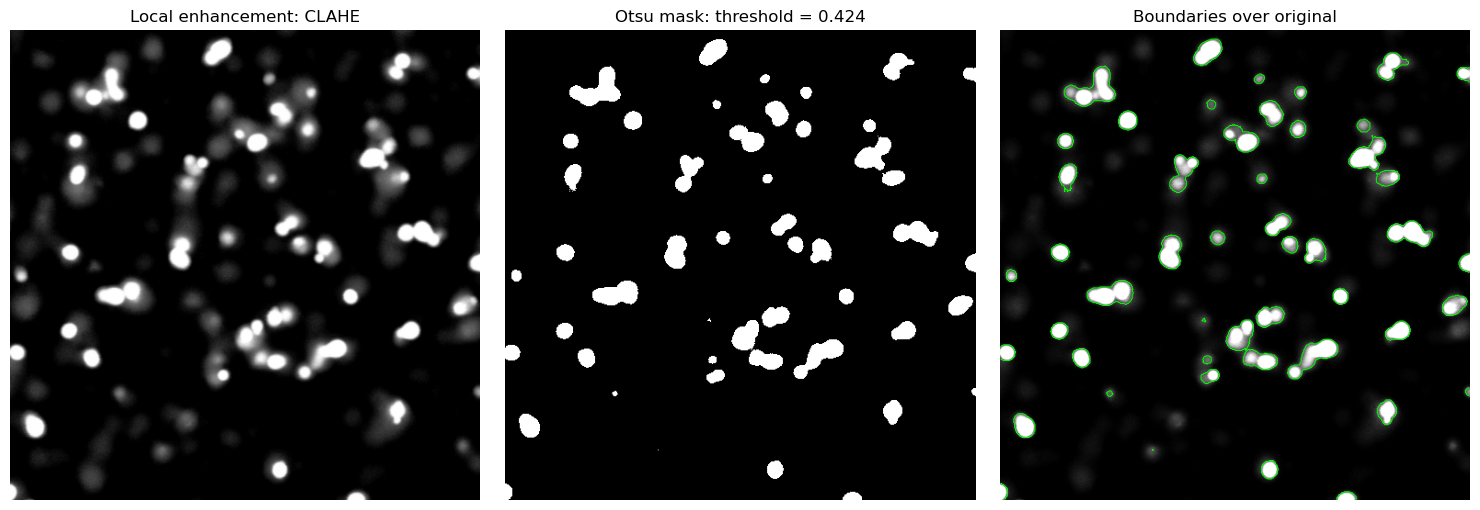

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import exposure, filters

original = raw[0].astype(np.float64, copy=True)

# Same normalization and smoothing as the global comparison.
low, high = np.percentile(original, (2, 98))
if high <= low:
    raise ValueError("Percentile range is constant; choose wider percentiles.")

normalized = np.clip((original - low) / (high - low), 0, 1)


smooth = filters.gaussian(normalized, sigma=0.5, preserve_range=True)

# LOCAL contrast enhancement.
local_image = exposure.equalize_adapthist(
    smooth,
    kernel_size=128,   # Contextual tile size in pixels.
    clip_limit=0.01,  # Higher values allow stronger contrast enhancement.
)

# Calculate and apply Otsu's threshold.
local_threshold = filters.threshold_otsu(local_image)
local_mask = local_image > local_threshold

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(local_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Local enhancement: CLAHE")

axes[1].imshow(local_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Otsu mask: threshold = {local_threshold:.3f}")

axes[2].imshow(
    original, cmap="gray", vmin=original.min(), vmax=original.max()
)
axes[2].contour(local_mask.astype(float), levels=[0.5],
                colors="lime", linewidths=0.7)
axes[2].set_title("Boundaries over original")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

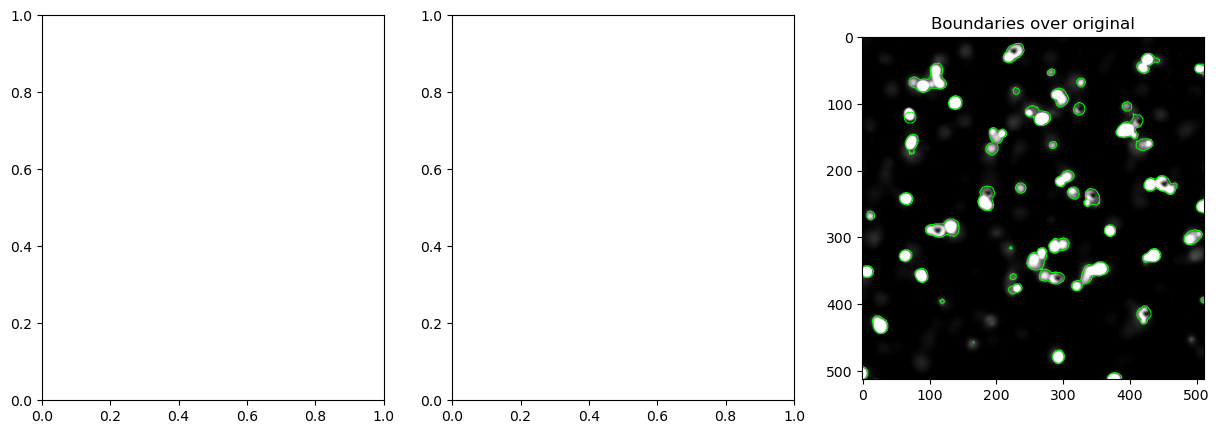

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
original = raw[1].astype(np.float64, copy=True)

axes[2].imshow(
    original, cmap="gray", vmin=original.min(), vmax=original.max()
)
axes[2].contour(local_mask.astype(float), levels=[0.5],
                colors="lime", linewidths=0.7)
axes[2].set_title("Boundaries over original")
plt.show()